# 02 · Arquitecturas y entrenamiento
**Proyecto final — Redes Neuronales y Aprendizaje Profundo (EAFIT)** · Clasificación de enfermedades foliares del café

Se entrenan y comparan tres familias de modelos sobre BRACOL (5 clases: sana, minador, roya, phoma, cercospora):

| Corrida | Arquitectura | Referencia | Rol |
|---|---|---|---|
| `cnn_base` | CNN de 4 bloques entrenada **desde cero** | — | Línea base |
| `effnet_b0` | **EfficientNet-B0** preentrenada (ImageNet-1k), fine-tuning completo | Tan & Le, ICML 2019 | Modelo principal |
| `vit_tiny` | **ViT-Tiny/16** preentrenado (ImageNet-21k → 1k), fine-tuning completo | Dosovitskiy et al., ICLR 2021 | Comparación CNN vs. Transformer |
| `effnet_b0_sinaug` | EfficientNet-B0 solo con volteos | — | **Ablación** del aumento de datos |

**Modificaciones respecto a los modelos originales:** se reemplaza la capa de clasificación (1000 → 5 salidas) y se añade dropout
antes de ella (0.3 en EfficientNet, 0.1 en ViT). Todo el resto de la red se ajusta (*fine-tuning* completo).

Código fuente en `src/` (`data.py`, `models.py`, `train.py`, `evaluate.py`).

In [1]:
# ===== Configuración del entorno (Colab o local) =====
import os, sys, json, shutil, zipfile, time
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/drive/MyDrive").exists():          # por si Drive ya está montado
        from google.colab import drive
        drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/ProyectoCafe")     # aquí está src/ y se guardan los resultados
    ROOT = Path("/content/proyecto")
    shutil.copytree(DRIVE / "src", ROOT / "src", dirs_exist_ok=True)
    (ROOT / "src" / "__init__.py").touch()
    os.environ["PROYECTO_ROOT"], os.environ["PROYECTO_OUT"] = str(ROOT), str(DRIVE)
    !pip -q install timm
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.environ.setdefault("PROYECTO_ROOT", str(ROOT)); os.environ.setdefault("PROYECTO_OUT", str(ROOT))
    DRIVE = Path(os.environ["PROYECTO_OUT"])
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src import config as C
C.FIG.mkdir(parents=True, exist_ok=True); C.RUNS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE, "| ROOT:", ROOT, "| salidas:", C.OUT)

Dispositivo: cpu | ROOT: C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final | salidas: C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final


In [2]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv 2>/dev/null || echo "sin GPU NVIDIA"
from src.train import hardware_info
import platform, psutil
hw = hardware_info(); hw["ram_gb"] = round(psutil.virtual_memory().total / 1e9, 1); hw["cpu_cores"] = os.cpu_count()
print(json.dumps(hw, indent=2))
json.dump(hw, open(C.RUNS / "hardware.json", "w"), indent=2)

"sin GPU NVIDIA"


El sistema no puede encontrar la ruta especificada.


{
  "python": "3.13.7",
  "torch": "2.15.0+cpu",
  "cpu": "Intel64 Family 6 Model 140 Stepping 2, GenuineIntel",
  "ram_gb": 21.2,
  "cpu_cores": 8
}


## 1. Datos y preprocesamiento
- **Letterbox 256×256**: se conserva la relación de aspecto (las lesiones no se deforman) y se rellena con el color medio de ImageNet,
  que tras la normalización vale ≈ 0, por lo que el relleno no aporta información.
- Imágenes cacheadas como tensores `uint8` para que la GPU no espere al disco.
- **Aumento (solo entrenamiento):** `RandomResizedCrop(224, escala 0.7–1)`, volteos H/V, rotaciones de 90° (la orientación de la hoja
  es arbitraria: en BRACOL es horizontal y en campo suele ser vertical), `ColorJitter` (brillo, contraste y saturación ±30 %).
- **Validación y prueba:** solo `Resize(224)` + normalización ImageNet (μ, σ de ImageNet porque los modelos fueron preentrenados ahí).

In [3]:
# ===== Datos: descarga + versiones RoCoLe + caché uint8 (letterbox 256) =====
from src.data import (download_bracol, download_rocole, build_rocole_versions, build_tables,
                      get_caches, load_tables, split_fingerprint)
DRIVE_CACHE = DRIVE / "cache"
names = ["bracol", "rocole_raw", "rocole_crop", "rocole_mask"]
tables = ["bracol_leaf.csv", "rocole.csv", "meta.json"]
if IN_COLAB and DRIVE_CACHE.exists():                      # reutiliza caché y tablas de una sesión anterior
    C.CACHE.mkdir(parents=True, exist_ok=True); C.PROC.mkdir(parents=True, exist_ok=True)
    for f in list(DRIVE_CACHE.glob("*.pt")) + [DRIVE_CACHE / t for t in tables if (DRIVE_CACHE / t).exists()]:
        dst = (C.CACHE if f.suffix == ".pt" else C.PROC) / f.name
        if not dst.exists():
            shutil.copy(f, dst)
if not all((C.CACHE / f"{n}.pt").exists() for n in names) or not (C.PROC / "bracol_leaf.csv").exists():
    t = time.time()
    download_bracol(); download_rocole(); build_tables(); build_rocole_versions()
    print(f"Descarga y preprocesamiento: {time.time() - t:.0f} s")
fp = split_fingerprint()
print("Huella de la partición:", fp)
assert fp == "bd076d1914a2", "La partición no coincide con la del notebook 01"
caches = get_caches()
GUARDAR_CACHE = IN_COLAB and os.environ.get("CACHE_EN_DRIVE", "1") == "1"   # ~1.2 GB en Drive (opcional)
if GUARDAR_CACHE and not all((DRIVE_CACHE / f"{n}.pt").exists() for n in names):
    DRIVE_CACHE.mkdir(parents=True, exist_ok=True)
    for n in names:
        shutil.copy(C.CACHE / f"{n}.pt", DRIVE_CACHE / f"{n}.pt")
    for t in tables:
        shutil.copy(C.PROC / t, DRIVE_CACHE / t)
bra, roc = load_tables()
print({k: tuple(v.shape) for k, v in caches.items()})
print(bra.split.value_counts().to_dict())

Huella de la partición: bd076d1914a2


{'bracol': (1685, 3, 256, 256), 'rocole_raw': (1560, 3, 256, 256), 'rocole_crop': (1560, 3, 256, 256), 'rocole_mask': (1560, 3, 256, 256)}
{'train': 1179, 'test': 253, 'val': 253}


C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\src\data.py:214: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  self.x, self.y, self.t = x, torch.as_tensor(np.asarray(y), dtype=torch.long), transform


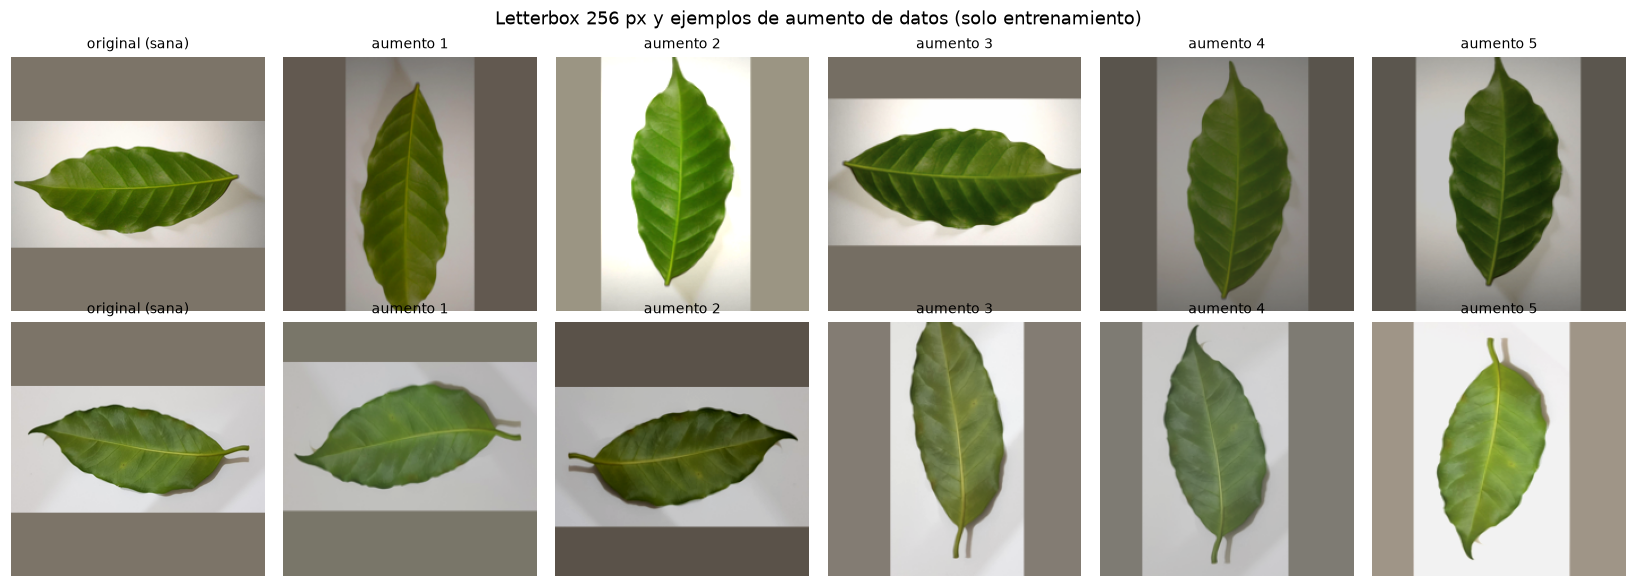

In [4]:
from src.data import TensorImageDataset, get_transforms, denormalize
ds = TensorImageDataset(caches["bracol"][:8], bra.label.values[:8], get_transforms("train"))
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for r, idx in enumerate([0, 700]):
    axes[r, 0].imshow(caches["bracol"][idx].permute(1, 2, 0)); axes[r, 0].set_title(f"original ({C.CLASSES[bra.label[idx]]})", fontsize=9)
    ds_i = TensorImageDataset(caches["bracol"][idx:idx+1], [0], get_transforms("train"))
    for k in range(1, 6):
        axes[r, k].imshow(denormalize(ds_i[0][0])); axes[r, k].set_title(f"aumento {k}", fontsize=9)
for a in axes.ravel(): a.axis("off")
fig.suptitle("Letterbox 256 px y ejemplos de aumento de datos (solo entrenamiento)")
plt.tight_layout(); plt.savefig(C.FIG / "02_aumento_datos.png"); plt.show()

## 2. Arquitecturas
- **CNN base:** 4 bloques `[Conv3×3 → BN → ReLU] ×2 → MaxPool2×2` (32, 64, 128, 256 filtros) → *Global Average Pooling* → Dropout(0.3) → FC(5).
  Entrada 3×224×224 → mapa 256×14×14 → vector 256 → 5 logits.
- **EfficientNet-B0:** stem Conv3×3 (32) + 16 bloques **MBConv** (convolución *inverted residual*: expansión 1×1 → convolución
  *depthwise* 3×3/5×5 → *Squeeze-and-Excitation* → proyección 1×1, con conexión residual) agrupados en 7 etapas; Conv1×1 (1280) → GAP → FC.
  Su escalamiento compuesto (profundidad, ancho y resolución) logra alta precisión con pocos parámetros y FLOPs (≈0.39 GFLOPs).
- **ViT-Tiny/16:** la imagen se corta en 14×14 = 196 *patches* de 16×16 que se proyectan a 192 dimensiones; se añade un token `[CLS]` y
  *embeddings* posicionales; 12 bloques Transformer (*multi-head self-attention* de 3 cabezas + MLP 768); el token `[CLS]` final → FC.

In [5]:
from src.models import build_model, count_params
rows = []
for arch in ["cnn", "effnet_b0", "vit_tiny"]:
    m = build_model(arch, pretrained=False)
    with torch.no_grad():
        out = m(torch.zeros(1, 3, C.IMG_SIZE, C.IMG_SIZE))
    rows.append({"arquitectura": arch, **count_params(m), "entrada": "3×224×224", "salida": tuple(out.shape)})
arch_df = pd.DataFrame(rows); display(arch_df)
arch_df.to_csv(C.RUNS / "arquitecturas.csv", index=False)
print(build_model("cnn"))

,arquitectura,total,entrenables,entrada,salida
0,cnn,1174501,1174501,3×224×224,"(1, 5)"
1,effnet_b0,4013953,4013953,3×224×224,"(1, 5)"
2,vit_tiny,5525381,5525381,3×224×224,"(1, 5)"


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool

## 3. Configuración experimental
| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Optimizador | AdamW | Adam con *weight decay* desacoplado: estándar para fine-tuning de CNNs y Transformers |
| Learning rate | 1e-3 (CNN) · 3e-4 (EffNet) · 1e-4 (ViT) | Desde cero tolera LR alto; los preentrenados necesitan LR bajo para no destruir lo aprendido; los ViT son más sensibles |
| Programación del LR | *warmup* lineal 2 épocas + coseno | El *warmup* estabiliza el inicio (cabeza aleatoria); el coseno afina al final |
| Batch size | 32 | Compromiso entre memoria de GPU, ruido del gradiente y número de pasos (1179 imágenes → 36 pasos/época) |
| Épocas máx. / paciencia | 40/10 (CNN) · 25/8 (preentrenados) | *Early stopping* con F1-macro de validación |
| Pérdida | Entropía cruzada **ponderada por clase** + *label smoothing* 0.1 | Desbalance 3.6× (cercospora minoritaria); el *smoothing* reduce la sobreconfianza |
| Weight decay | 1e-4 / 1e-2 / 5e-2 | Regularización; mayor en ViT (más propenso a sobreajustar con pocos datos) |
| Precisión | Mixta FP16 (AMP) en GPU | Acelera el entrenamiento ~2× sin pérdida de exactitud |
| Selección del modelo | Época con **mayor F1-macro en validación** | El conjunto de prueba no se usa para ninguna decisión |

In [6]:
from src.train import RUNS_CFG, DEFAULTS, train
display(pd.DataFrame({k: {**DEFAULTS, **v} for k, v in RUNS_CFG.items()}).T)

,batch,warmup,label_smoothing,seed,max_train,arch,lr,wd,epochs,aug,patience
cnn_base,32,2,0.1,42,None,cnn,0.001,0.0001,40,train,10
effnet_b0,32,2,0.1,42,None,effnet_b0,0.0003,0.01,25,train,8
vit_tiny,32,2,0.1,42,None,vit_tiny,0.0001,0.05,25,train,8
effnet_b0_sinaug,32,2,0.1,42,None,effnet_b0,0.0003,0.01,25,train_min,8


## 4. Entrenamiento
Cada corrida guarda `history.csv`, `best.pt` y `summary.json` en `runs/<modelo>/`. Si una corrida ya existe se omite y se cargan sus resultados.

In [7]:
summaries = {}
for run in RUNS_CFG:
    summaries[run] = train(run, caches=caches)
    print(f"→ {run}: mejor F1 val = {summaries[run]['best_val_f1']:.4f} (época {summaries[run]['best_epoch']}), "
          f"{summaries[run]['train_time_s'] / 60:.1f} min\n")

[cnn_base] ya entrenado → se omite (borra C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\runs\cnn_base para reentrenar)
→ cnn_base: mejor F1 val = 0.8765 (época 19), 105.3 min

[effnet_b0] ya entrenado → se omite (borra C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\runs\effnet_b0 para reentrenar)
→ effnet_b0: mejor F1 val = 0.9150 (época 19), 88.6 min

[vit_tiny] ya entrenado → se omite (borra C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\runs\vit_tiny para reentrenar)
→ vit_tiny: mejor F1 val = 0.9349 (época 18), 53.3 min

[effnet_b0_sinaug] ya entrenado → se omite (borra C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\runs\effnet_b0_sinaug para reentrenar)
→ effnet_b0_sinaug: mejor F1 val = 0.9129 (época 22), 76.3 min



In [8]:
# Registro de consola del entrenamiento (si las corridas se lanzaron con `python -m src.train`)
log = C.RUNS / "train_log.txt"
print(log.read_text(encoding="utf8", errors="replace") if log.exists() else "Sin registro externo: ver salida de la celda anterior.")

  ds_tr = TensorImageDataset(X[tr], bra.label.values[tr], get_transforms(cfg["aug"]))
[effnet_b0] ep 01 | loss 4.010/1.771 | F1 0.242/0.552 | 223.9s *
[effnet_b0] ep 02 | loss 2.166/1.219 | F1 0.523/0.675 | 222.4s *
[effnet_b0] ep 03 | loss 1.538/1.045 | F1 0.633/0.704 | 226.2s *
[effnet_b0] ep 04 | loss 1.299/0.898 | F1 0.679/0.811 | 219.5s *
[effnet_b0] ep 05 | loss 1.071/0.941 | F1 0.756/0.784 | 229.9s
[effnet_b0] ep 06 | loss 1.020/0.841 | F1 0.760/0.844 | 241.0s *
[effnet_b0] ep 07 | loss 0.933/0.845 | F1 0.809/0.833 | 251.0s
[effnet_b0] ep 08 | loss 0.951/0.795 | F1 0.781/0.859 | 251.0s *
[effnet_b0] ep 09 | loss 0.915/0.743 | F1 0.804/0.860 | 258.1s *
[effnet_b0] ep 10 | loss 0.886/0.724 | F1 0.807/0.846 | 207.2s
[effnet_b0] ep 11 | loss 0.817/0.745 | F1 0.834/0.855 | 194.3s
[effnet_b0] ep 12 | loss 0.783/0.718 | F1 0.845/0.895 | 198.5s *
[effnet_b0] ep 13 | loss 0.805/0.714 | F1 0.843/0.867 | 208.0s
[effnet_b0] ep 14 | loss 0.760/0.699 | F1 0.854/0.863 | 184.5s
[effnet_b0] ep 1

## 5. Curvas de aprendizaje

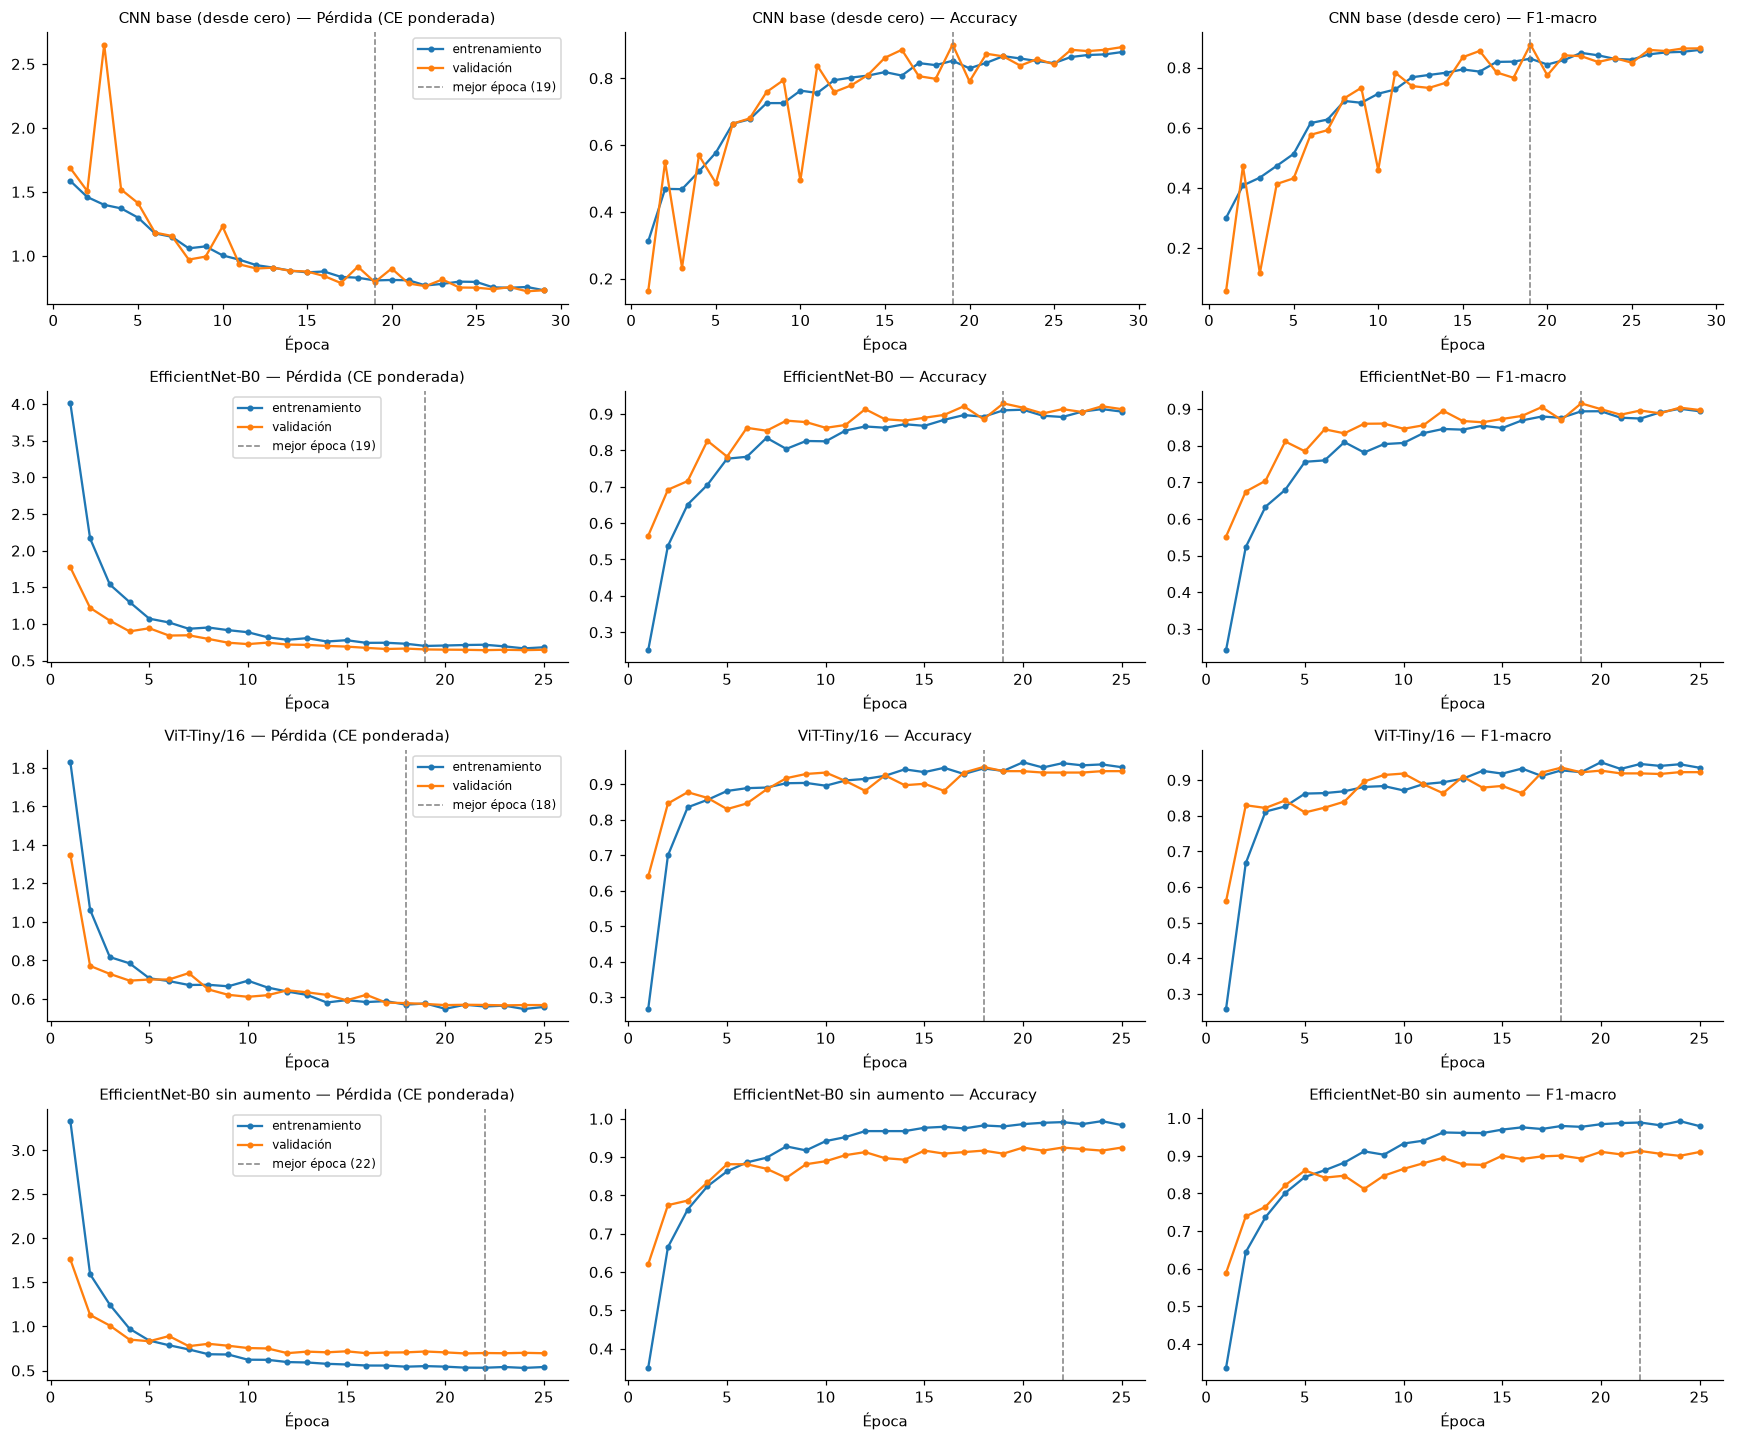

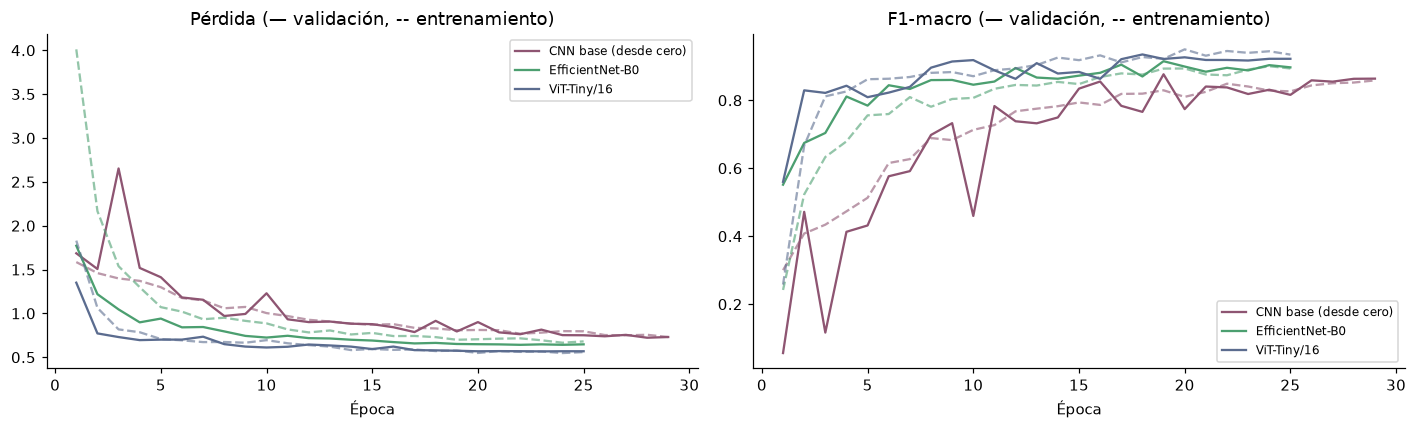

In [9]:
NOMBRES = {"cnn_base": "CNN base (desde cero)", "effnet_b0": "EfficientNet-B0", "vit_tiny": "ViT-Tiny/16",
           "effnet_b0_sinaug": "EfficientNet-B0 sin aumento"}
fig, axes = plt.subplots(len(RUNS_CFG), 3, figsize=(16, 3.3 * len(RUNS_CFG)))
for r, run in enumerate(RUNS_CFG):
    h = pd.read_csv(C.RUNS / run / "history.csv"); be = summaries[run]["best_epoch"]
    for ax, met, ttl in zip(axes[r], ["loss", "acc", "f1"], ["Pérdida (CE ponderada)", "Accuracy", "F1-macro"]):
        ax.plot(h.epoch, h[f"train_{met}"], "-o", ms=3, label="entrenamiento")
        ax.plot(h.epoch, h[f"val_{met}"], "-o", ms=3, label="validación")
        ax.axvline(be, color="gray", ls="--", lw=1, label=f"mejor época ({be})")
        ax.set_title(f"{NOMBRES[run]} — {ttl}", fontsize=10); ax.set_xlabel("Época")
    axes[r, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(C.FIG / "02_curvas_todas.png"); plt.show()

# figura compacta para la presentación: F1 y pérdida de validación de los 3 modelos principales
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for run, c in zip(["cnn_base", "effnet_b0", "vit_tiny"], ["#8E5572", "#4C9F70", "#5B6C8F"]):
    h = pd.read_csv(C.RUNS / run / "history.csv")
    axes[0].plot(h.epoch, h.train_loss, "--", color=c, alpha=.6); axes[0].plot(h.epoch, h.val_loss, "-", color=c, label=NOMBRES[run])
    axes[1].plot(h.epoch, h.train_f1, "--", color=c, alpha=.6); axes[1].plot(h.epoch, h.val_f1, "-", color=c, label=NOMBRES[run])
axes[0].set_title("Pérdida (— validación, -- entrenamiento)"); axes[1].set_title("F1-macro (— validación, -- entrenamiento)")
for a in axes: a.set_xlabel("Época"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(C.FIG / "02_curvas_comparacion.png"); plt.show()

In [10]:
res = []
for run, s in summaries.items():
    h = pd.read_csv(C.RUNS / run / "history.csv"); b = h.loc[h.epoch == s["best_epoch"]].iloc[0]
    res.append({"corrida": run, "parámetros (M)": round(s["params"]["total"] / 1e6, 2), "épocas": s["epochs_run"],
                "mejor época": s["best_epoch"], "F1 train": round(b.train_f1, 4), "F1 val": round(b.val_f1, 4),
                "brecha F1 (train−val)": round(b.train_f1 - b.val_f1, 4), "loss train": round(b.train_loss, 4),
                "loss val": round(b.val_loss, 4), "tiempo (min)": round(s["train_time_s"] / 60, 2),
                "s/época": round(h.epoch_time_s.mean(), 1)})
train_df = pd.DataFrame(res); display(train_df)
train_df.to_csv(C.RUNS / "resumen_entrenamiento.csv", index=False)

,corrida,parámetros (M),épocas,mejor época,F1 train,F1 val,brecha F1 (train−val),loss train,loss val,tiempo (min),s/época
0,cnn_base,1.17,29,19,0.8294,0.8765,-0.0471,0.8074,0.7939,105.28,217.8
1,effnet_b0,4.01,25,19,0.8933,0.9150,-0.0217,0.6992,0.6512,88.59,212.6
2,vit_tiny,5.53,25,18,0.9272,0.9349,-0.0076,0.5703,0.5784,53.27,127.8
3,effnet_b0_sinaug,4.01,25,22,0.9884,0.9129,0.0756,0.5318,0.6989,76.32,183.1


### Análisis de las curvas
Con aumento de datos no hay sobreajuste: el F1 de entrenamiento (medido con imágenes aumentadas y dropout) queda en o por debajo del de validación, y las curvas aún suben levemente al final (ligero subajuste por el presupuesto de épocas en CPU). ViT converge más rápido (F1 val 0,83 en la época 2); la CNN desde cero es inestable (caídas de la validación hasta 0,46) y el early stopping la detuvo en la época 29. En cambio, la ablación sin aumento sí sobreajusta: F1 train 0,988 vs. val 0,913 y pérdida de validación estancada mientras la de entrenamiento baja. El piso de pérdida (≈ 0,55) se debe al label smoothing.

**Hardware:** Colab no asignó GPU (cuota gratuita agotada), por lo que los cuatro modelos se entrenaron en CPU (Intel Core i5-1155G7, 4 núcleos, 20 GB RAM): ViT ≈ 2,1 min/época, EfficientNet-B0 ≈ 3,5 min/época, total ≈ 5,4 h.